# V4 PIP3 Model — All Figures
All model setup (ODE, parameters, initial conditions, simulations) lives in **Cell 1**.  
Every figure cell below references those shared variables directly

In [1]:
# ================================================================
# CELL 1 — SETUP: imports, model, parameters, ICs, simulations
# Run this cell before any figure cell.
# ================================================================

import numpy as np
from scipy.integrate import odeint
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.colors as mcolors
import colorcet as cc


# ----------------------------------------------------------------
# Reference concentration (used to convert bimolecular rates)
# ----------------------------------------------------------------
C_ref = 1e-6  # M  (1 µM)

# ----------------------------------------------------------------
# RATE CONSTANTS
# ----------------------------------------------------------------

# Act FcR–IgG binding (Activating arm)
k_bind_A_real   = 6.51e3      # M⁻¹s⁻¹
k_unbind_A_real = 4.71e-3     # s⁻¹   KD_A = 0.724 µM
k_bind_A        = k_bind_A_real  * C_ref
k_unbind_A      = k_unbind_A_real

# FcRIIB–IgG binding (Inhibitory arm)
k_bind_B_real   = 3.8e5       # M⁻¹s⁻¹
k_unbind_B_real = 0.88        # s⁻¹   KD_B = 2.316 µM
k_bind_B        = k_bind_B_real  * C_ref
k_unbind_B      = k_unbind_B_real

# ITAM/ITIM phosphorylation
k_phos = 0.15   # s⁻¹

# Syk recruitment to pITAM
k_on_S_real = 1.5e5           # M⁻¹s⁻¹
k_on_S      = k_on_S_real * C_ref   # 0.15 s⁻¹ effective
k_off_S     = 0.13                   # s⁻¹

# PI3K recruitment to active Syk
k_on_PI3K_real = 3.34e6       # M⁻¹s⁻¹
k_on_PI3K      = k_on_PI3K_real * C_ref   # 3.34 s⁻¹ effective
k_off_PI3K     = 1.002                     # s⁻¹   kon × 300 nM

# PI3K catalysis
k_cat_pi3k = 0.975   # s⁻¹
Km_pip2    = 1.80    # µM

# SHIP1 recruitment to pITIM
k_on_SHIP1_real = 1.05e6      # M⁻¹s⁻¹
k_on_SHIP1      = k_on_SHIP1_real * C_ref   # 1.05 s⁻¹ effective
k_off_SHIP1     = 0.29                       # s⁻¹

# SHIP1 catalysis
k_cat_SHIP1 = 8.0    # s⁻¹
Km_PIP3     = 94.0   # µM

# ----------------------------------------------------------------
# PACKED PARAMETER LIST  (order must match ODE unpacking below)
# ----------------------------------------------------------------
params = [
    k_bind_A,    k_unbind_A,
    k_bind_B,    k_unbind_B,
    k_phos,
    k_on_S,      k_off_S,
    k_on_PI3K,   k_off_PI3K,
    k_cat_pi3k,  Km_pip2,
    k_on_SHIP1,  k_off_SHIP1, k_cat_SHIP1, Km_PIP3
]

# ----------------------------------------------------------------
# ODE SYSTEM — V4
#
# Species (14 total, indices):
#  [0]  FcR_A    — free Act FcR
#  [1]  FcR_Ab_A — Ab-bound Act FcR
#  [2]  FcRp_A   — phosphorylated Act FcR
#  [3]  FcR_B    — free FcRIIB
#  [4]  FcR_Ab_B — Ab-bound FcRIIB
#  [5]  FcRp_B   — phosphorylated FcRIIB
#  [6]  S        — Syk
#  [7]  PI3K     — membrane-recruited PI3K
#  [8]  SHIP1    — pITIM-recruited SHIP1
#  [9]  PIP2     — PI(4,5)P2
#  [10] PIP3     — PI(3,4,5)P3
#  [11] PI34P2   — PI(3,4)P2  (SHIP1 product)
#  [12] Ab_A     — Ab to act FcRs
#  [13] Ab_B     — Ab to FcRIIB
# ----------------------------------------------------------------
def pip_dynamics_model_v4(y, t, params):
    (FcR_A, FcR_Ab_A, FcRp_A,
     FcR_B, FcR_Ab_B, FcRp_B,
     S, PI3K, SHIP1,
     PIP2, PIP3, PI34P2,
     Ab_A, Ab_B) = y

    (k_bind_A, k_unbind_A,
     k_bind_B, k_unbind_B,
     k_phos,
     k_on_S,    k_off_S,
     k_on_PI3K, k_off_PI3K,
     k_cat_pi3k, Km_pip2,
     k_on_SHIP1, k_off_SHIP1, k_cat_SHIP1, Km_PIP3) = params

    # Activating arm
    dFcR_A    = -k_bind_A * Ab_A * FcR_A  + k_unbind_A * FcR_Ab_A
    dFcR_Ab_A =  k_bind_A * Ab_A * FcR_A  - k_unbind_A * FcR_Ab_A - k_phos * FcR_Ab_A
    dFcRp_A   =  k_phos * FcR_Ab_A
    dAb_A     = -k_bind_A * Ab_A * FcR_A  + k_unbind_A * FcR_Ab_A

    # Inhibitory arm
    dFcR_B    = -k_bind_B * Ab_B * FcR_B  + k_unbind_B * FcR_Ab_B
    dFcR_Ab_B =  k_bind_B * Ab_B * FcR_B  - k_unbind_B * FcR_Ab_B - k_phos * FcR_Ab_B
    dFcRp_B   =  k_phos * FcR_Ab_B
    dAb_B     = -k_bind_B * Ab_B * FcR_B  + k_unbind_B * FcR_Ab_B

    # Downstream recruitment
    dS     =  k_on_S     * FcRp_A  - k_off_S     * S
    dPI3K  =  k_on_PI3K  * S       - k_off_PI3K  * PI3K
    dSHIP1 =  k_on_SHIP1 * FcRp_B  - k_off_SHIP1 * SHIP1

    # Lipid dynamics
    pip3_gen  = k_cat_pi3k  * PI3K  * (PIP2  / (Km_pip2 + PIP2))
    pip3_cons = k_cat_SHIP1 * SHIP1 * (PIP3  / (Km_PIP3 + PIP3))

    dPIP2   = -pip3_gen
    dPIP3   =  pip3_gen - pip3_cons
    dPI34P2 =  pip3_cons

    return [dFcR_A, dFcR_Ab_A, dFcRp_A,
            dFcR_B, dFcR_Ab_B, dFcRp_B,
            dS, dPI3K, dSHIP1,
            dPIP2, dPIP3, dPI34P2,
            dAb_A, dAb_B]


# ----------------------------------------------------------------
# INITIAL CONDITIONS
# ----------------------------------------------------------------
Ab_molar   = 30e-9    # 30 nM total IgG
KD_IIIA_mae = 0.98e-6
KD_IIB_mae = 2.3e-6

Ab_A0 = Ab_molar / C_ref                               # 0.030  (30 nM)
Ab_B0 = Ab_molar * (KD_IIIA_mae / KD_IIB_mae) / C_ref  # ~0.01278 (12.78 nM)

# V4 with FcRIIB active (IgG + DNA)
y0 = [
    1.0, 0, 0,     # FcR_A, FcR_Ab_A, FcRp_A
    1.0, 0, 0,     # FcR_B, FcR_Ab_B, FcRp_B
    0,   0, 0,     # S,     PI3K,     SHIP1
    3.0, 0, 0,     # PIP2,  PIP3,     PI34P2
    Ab_A0, Ab_B0
]

# V4 without FcRIIB (Ab_B = 0, FcR_B = 0) (IgG ONLY)
y0_noiib = [1.0, 0, 0,  0, 0, 0,  0, 0, 0,  3.0, 0, 0,  Ab_A0, 0.0]


# ----------------------------------------------------------------
# TIME SPAN
# ----------------------------------------------------------------
t = np.linspace(0, 600, 1200)  # 10-minute simulation


# ----------------------------------------------------------------
# RUN SIMULATIONS
# ----------------------------------------------------------------
sol_v4       = odeint(pip_dynamics_model_v4, y0,       t, args=(params,), mxstep=10000)
sol_v4_noiib = odeint(pip_dynamics_model_v4, y0_noiib, t, args=(params,), mxstep=10000)

# Convenience aliases
pip3_v4       = sol_v4[:, 10]
pip3_v4_noiib = sol_v4_noiib[:, 10]


# ----------------------------------------------------------------
# SHARED PLOT STYLE
# ----------------------------------------------------------------
CV4_IIB   = 'darkred'
CV4_NOIIB = 'darkblue'
CTHR      = '#AAAAAA'
C_PIP2    = 'mediumorchid'
C_PIP3    = 'darkseagreen'
C_PI34P2  = 'indianred'

SPINE_LW  = 2.0
TICK_LW   = 2.0
TICK_LEN  = 5
LABEL_FS  = 6
TICK_FS   = 20

def style_ax(ax):
    """Apply consistent spine / tick styling to an Axes."""
    for spine in ax.spines.values():
        spine.set_linewidth(SPINE_LW)
    ax.tick_params(axis='both', which='major',
                   width=TICK_LW, length=TICK_LEN, labelsize=TICK_FS)

print('Setup complete — ready to plot.')


Setup complete — ready to plot.


## Figure 2 — PIP3 dynamics: FcRIIB active vs inactive

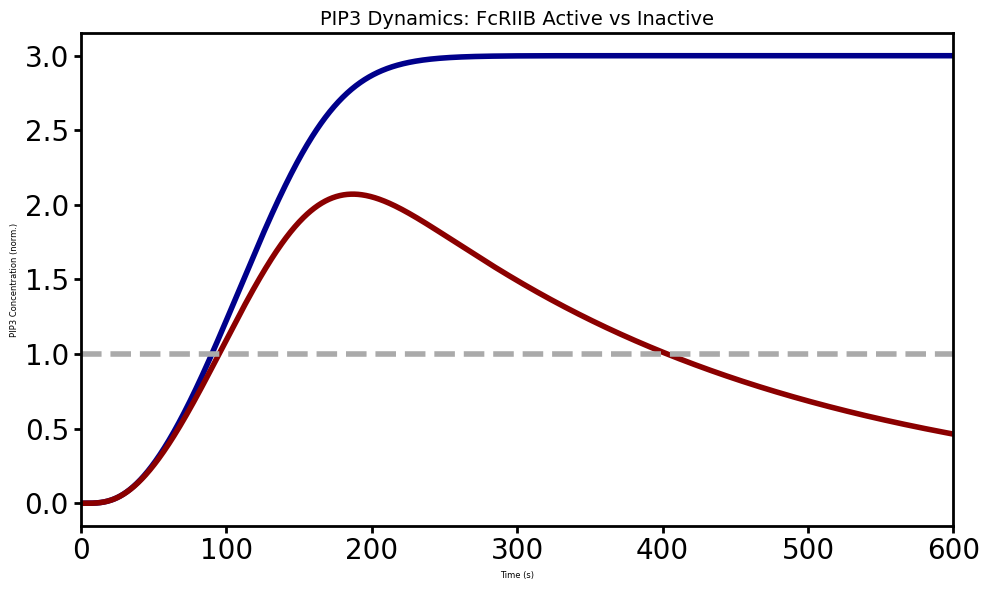

In [2]:
# Uses: t, pip3_v4, pip3_v4_noiib, CTHR, CV4_IIB, CV4_NOIIB, style_ax, LABEL_FS

fig, ax = plt.subplots(figsize=(10,6))

ax.plot(t, pip3_v4_noiib, color=CV4_NOIIB, lw=4, label='FcγRIIB Inactive')
ax.plot(t, pip3_v4,       color=CV4_IIB,  lw=4,           label='FcγRIIB Active')
ax.axhline(1, color=CTHR, ls='--', lw=4, label='Phagocytosis threshold')

ax.set_xlabel('Time (s)', fontsize=LABEL_FS)
ax.set_ylabel('PIP3 Concentration (norm.)', fontsize=LABEL_FS)
ax.set_title('PIP3 Dynamics: FcRIIB Active vs Inactive', fontsize=14)
#ax.legend(fontsize=12)
#ax.grid(True, alpha=0.25)
ax.set_xlim(0, 600)
style_ax(ax)

plt.tight_layout()
plt.show()
OUTFILE = "active_inactive"
fig.savefig(f"{OUTFILE}.pdf", bbox_inches="tight")   # vector, for further editing

## Figure 2 — All three lipid species (FcRIIB active)

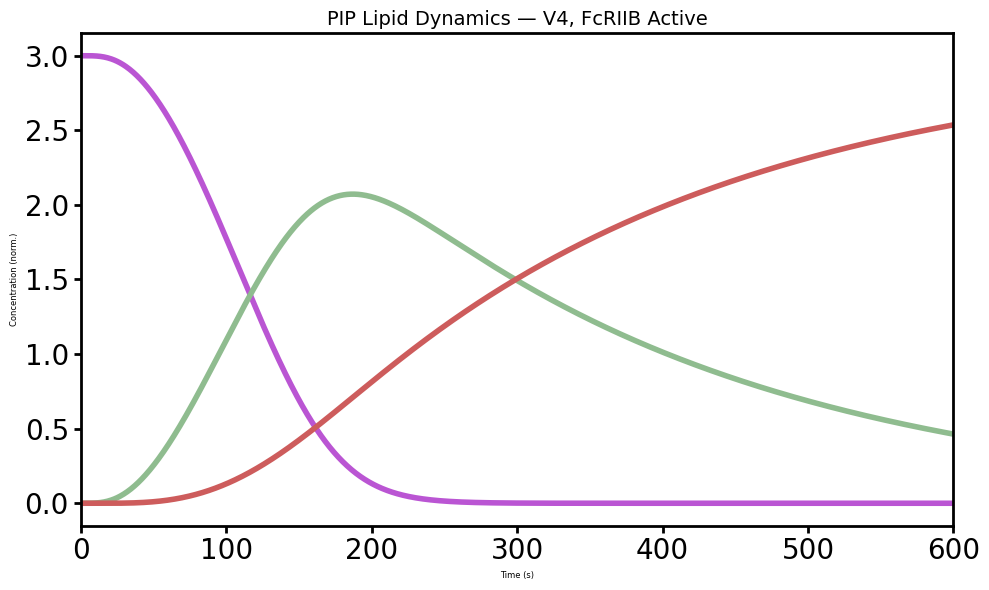

In [ ]:
# Uses: t, sol_v4, CTHR, C_PIP2, C_PIP3, C_PI34P2, style_ax, LABEL_FS

fig, ax = plt.subplots(figsize=(10,6))

ax.plot(t, sol_v4[:, 9],  color=C_PIP2,   lw=4, label='PI(4,5)P₂')
ax.plot(t, sol_v4[:, 10], color=C_PIP3,   lw=4, label='PI(3,4,5)P₃')
ax.plot(t, sol_v4[:, 11], color=C_PI34P2, lw=4, label='PI(3,4)P₂')
#ax.axhline(1, color=CTHR, ls='--', lw=4)

ax.set_xlabel('Time (s)', fontsize=LABEL_FS)
ax.set_ylabel('Concentration (norm.)', fontsize=LABEL_FS)
ax.set_title('PIP Lipid Dynamics — V4, FcRIIB Active', fontsize=14)
#ax.legend(fontsize=12)
#ax.grid(True, alpha=0.25)
ax.set_xlim(0, 600)
style_ax(ax)

plt.tight_layout()
plt.show()
OUTFILE = "with IIB"
fig.savefig(f"{OUTFILE}.pdf", bbox_inches="tight")   # vector, for further editing

## Figure 2 — All three lipid species (FcRIIB inactive)

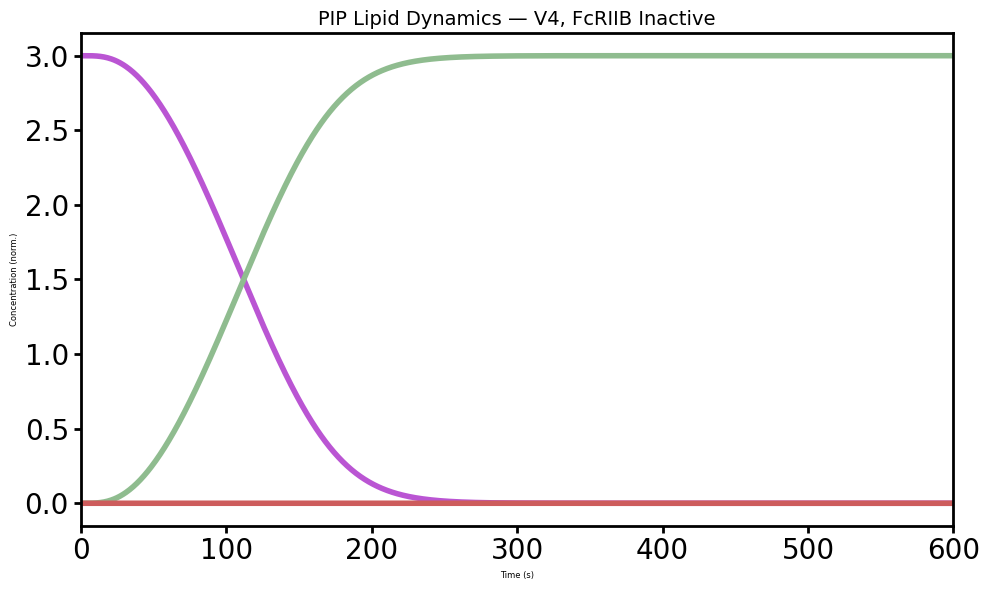

In [ ]:
# Uses: t, sol_v4_noiib, CTHR, C_PIP2, C_PIP3, C_PI34P2, style_ax, LABEL_FS
# FcRIIB-inactive counterpart to the three-lipid plot above (no IIB stimulation:
# Ab_B = 0, FcR_B = 0). With no SHIP1 recruitment, PIP3 is not converted to
# PI(3,4)P2, so PI34P2 stays ~0 and PIP3 accumulates to its unsuppressed maximum.

fig, ax = plt.subplots(figsize=(10,6))

ax.plot(t, sol_v4_noiib[:, 9],  color=C_PIP2,   lw=4, label='PI(4,5)P₂')
ax.plot(t, sol_v4_noiib[:, 10], color=C_PIP3,   lw=4, label='PI(3,4,5)P₃')
ax.plot(t, sol_v4_noiib[:, 11], color=C_PI34P2, lw=4, label='PI(3,4)P₂')
#ax.axhline(1, color=CTHR, ls='--', lw=4)

ax.set_xlabel('Time (s)', fontsize=LABEL_FS)
ax.set_ylabel('Concentration (norm.)', fontsize=LABEL_FS)
ax.set_title('PIP Lipid Dynamics — V4, FcRIIB Inactive', fontsize=14)
#ax.legend(fontsize=12)
#ax.grid(True, alpha=0.25)
ax.set_xlim(0, 600)
style_ax(ax)

plt.tight_layout()
plt.show()
OUTFILE = "NO iib"
fig.savefig(f"{OUTFILE}.pdf", bbox_inches="tight")   # vector, for further editing

## Figure 3 — Sweep: varying FcRIIIA activating input

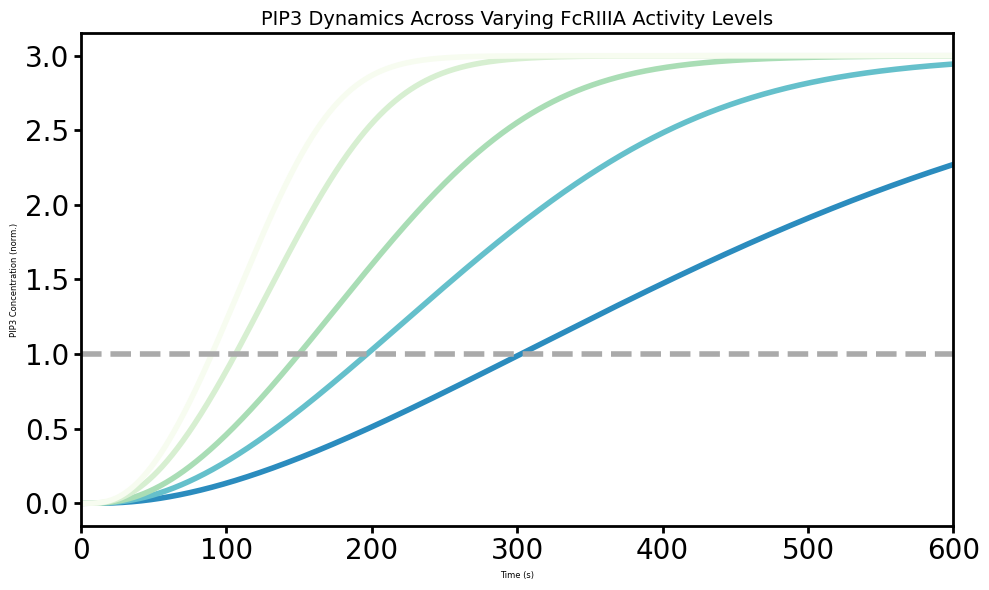

In [ ]:
# Uses: params, y0_noiib, t, style_ax, CTHR, LABEL_FS
# Knob: multiplier on phospho-FcRIIIA (FcRp_A) where it drives Syk recruitment.
#   dS = k_on_S * (fcra_scale * FcRp_A) - k_off_S * S

def pip_dynamics_model_v4_fcra(y, t, params, fcra_scale):
    (FcR_A, FcR_Ab_A, FcRp_A, FcR_B, FcR_Ab_B, FcRp_B,
     S, PI3K, SHIP1, PIP2, PIP3, PI34P2, Ab_A, Ab_B) = y
    (k_bind_A, k_unbind_A, k_bind_B, k_unbind_B, k_phos,
     k_on_S, k_off_S, k_on_PI3K, k_off_PI3K, k_cat_pi3k, Km_pip2,
     k_on_SHIP1, k_off_SHIP1, k_cat_SHIP1, Km_PIP3) = params

    dFcR_A    = -k_bind_A*Ab_A*FcR_A + k_unbind_A*FcR_Ab_A
    dFcR_Ab_A =  k_bind_A*Ab_A*FcR_A - k_unbind_A*FcR_Ab_A - k_phos*FcR_Ab_A
    dFcRp_A   =  k_phos*FcR_Ab_A
    dAb_A     = -k_bind_A*Ab_A*FcR_A + k_unbind_A*FcR_Ab_A

    dFcR_B    = -k_bind_B*Ab_B*FcR_B + k_unbind_B*FcR_Ab_B
    dFcR_Ab_B =  k_bind_B*Ab_B*FcR_B - k_unbind_B*FcR_Ab_B - k_phos*FcR_Ab_B
    dFcRp_B   =  k_phos*FcR_Ab_B
    dAb_B     = -k_bind_B*Ab_B*FcR_B + k_unbind_B*FcR_Ab_B

    dS     = k_on_S*(fcra_scale*FcRp_A) - k_off_S*S     # <-- pFcRIIIA swept
    dPI3K  = k_on_PI3K*S    - k_off_PI3K*PI3K
    dSHIP1 = k_on_SHIP1*FcRp_B - k_off_SHIP1*SHIP1

    pip3_gen  = k_cat_pi3k  * PI3K  * (PIP2 / (Km_pip2 + PIP2))
    pip3_cons = k_cat_SHIP1 * SHIP1 * (PIP3 / (Km_PIP3 + PIP3))
    dPIP2, dPIP3, dPI34P2 = -pip3_gen, pip3_gen - pip3_cons, pip3_cons

    return [dFcR_A, dFcR_Ab_A, dFcRp_A, dFcR_B, dFcR_Ab_B, dFcRp_B,
            dS, dPI3K, dSHIP1, dPIP2, dPIP3, dPI34P2, dAb_A, dAb_B]

fcra_scales  = [0.1, 0.21, 0.35, 0.7, 1]    # phospho-FcRIIIA activity multiplier
cmap         = plt.cm.GnBu_r
colors_sweep = [cmap(0.25 + 0.75 * i / (len(fcra_scales) - 1)) for i in range(len(fcra_scales))]

fig, ax = plt.subplots(figsize=(10, 6))

for scale, color in zip(fcra_scales, colors_sweep):
    sol_sweep = odeint(pip_dynamics_model_v4_fcra, y0_noiib, t,
                       args=(params, scale), mxstep=10000)
    label = ('FcRIIIA hyperactive' if scale > 1 else
             'FcRIIIA inhibited'   if scale < 1 else 'nominal')
    ax.plot(t, sol_sweep[:, 10], color=color, lw=4,
            label=f'{scale:.2f}× pFcRIIIA')

ax.axhline(1, color=CTHR, ls='--', lw=4)
ax.set_xlabel('Time (s)', fontsize=LABEL_FS)
ax.set_ylabel('PIP3 Concentration (norm.)', fontsize=LABEL_FS)
ax.set_title('PIP3 Dynamics Across Varying FcRIIIA Activity Levels', fontsize=14)
#ax.legend(fontsize=10, title='FcRIIIIA activity')
#ax.grid(True, alpha=0.25)
ax.set_xlim(0, 600)
style_ax(ax)

plt.tight_layout()
plt.show()
OUTFILE = "IIIA sweep"
fig.savefig(f"{OUTFILE}.pdf", bbox_inches="tight")   # vector, for further editing

## Figure 3 — IIB sweep

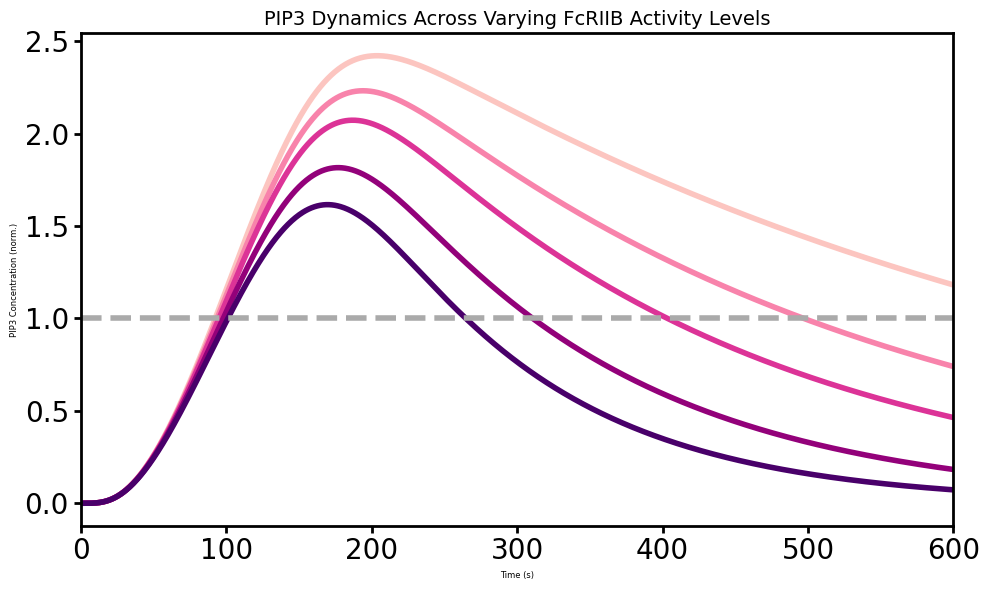

In [ ]:
# Uses: params, y0, t, style_ax, CTHR, LABEL_FS
# Knob: multiplier on phospho-FcRIIB (FcRp_B) where it drives SHIP1 recruitment.
#   dSHIP1 = k_on_SHIP1 * (fcrb_scale * FcRp_B) - k_off_SHIP1 * SHIP1

def pip_dynamics_model_v4_fcrb(y, t, params, fcrb_scale):
    (FcR_A, FcR_Ab_A, FcRp_A, FcR_B, FcR_Ab_B, FcRp_B,
     S, PI3K, SHIP1, PIP2, PIP3, PI34P2, Ab_A, Ab_B) = y
    (k_bind_A, k_unbind_A, k_bind_B, k_unbind_B, k_phos,
     k_on_S, k_off_S, k_on_PI3K, k_off_PI3K, k_cat_pi3k, Km_pip2,
     k_on_SHIP1, k_off_SHIP1, k_cat_SHIP1, Km_PIP3) = params

    dFcR_A    = -k_bind_A*Ab_A*FcR_A + k_unbind_A*FcR_Ab_A
    dFcR_Ab_A =  k_bind_A*Ab_A*FcR_A - k_unbind_A*FcR_Ab_A - k_phos*FcR_Ab_A
    dFcRp_A   =  k_phos*FcR_Ab_A
    dAb_A     = -k_bind_A*Ab_A*FcR_A + k_unbind_A*FcR_Ab_A

    dFcR_B    = -k_bind_B*Ab_B*FcR_B + k_unbind_B*FcR_Ab_B
    dFcR_Ab_B =  k_bind_B*Ab_B*FcR_B - k_unbind_B*FcR_Ab_B - k_phos*FcR_Ab_B
    dFcRp_B   =  k_phos*FcR_Ab_B
    dAb_B     = -k_bind_B*Ab_B*FcR_B + k_unbind_B*FcR_Ab_B

    dS     = k_on_S*FcRp_A - k_off_S*S
    dPI3K  = k_on_PI3K*S   - k_off_PI3K*PI3K
    dSHIP1 = k_on_SHIP1*(fcrb_scale*FcRp_B) - k_off_SHIP1*SHIP1  # <-- pFcRIIB swept

    pip3_gen  = k_cat_pi3k  * PI3K  * (PIP2 / (Km_pip2 + PIP2))
    pip3_cons = k_cat_SHIP1 * SHIP1 * (PIP3 / (Km_PIP3 + PIP3))
    dPIP2, dPIP3, dPI34P2 = -pip3_gen, pip3_gen - pip3_cons, pip3_cons

    return [dFcR_A, dFcR_Ab_A, dFcRp_A, dFcR_B, dFcR_Ab_B, dFcRp_B,
            dS, dPI3K, dSHIP1, dPIP2, dPIP3, dPI34P2, dAb_A, dAb_B]

fcrb_scales  = [0.5, 0.75, 1, 1.5, 2]    # phospho-FcRIIB activity multiplier
cmap         = plt.cm.RdPu
colors_sweep = [cmap(0.25 + 0.75 * i / (len(fcrb_scales) - 1)) for i in range(len(fcrb_scales))]

fig, ax = plt.subplots(figsize=(10, 6))

for scale, color in zip(fcrb_scales, colors_sweep):
    sol_sweep = odeint(pip_dynamics_model_v4_fcrb, y0, t,
                       args=(params, scale), mxstep=10000)
    label = ('FcRIIB hyperactive' if scale > 1 else
             'FcRIIB inhibited'   if scale < 1 else 'nominal')
    ax.plot(t, sol_sweep[:, 10], color=color, lw=4,
            label=f'{scale:.2f}× pFcRIIB')

ax.axhline(1, color=CTHR, ls='--', lw=4)
ax.set_xlabel('Time (s)', fontsize=LABEL_FS)
ax.set_ylabel('PIP3 Concentration (norm.)', fontsize=LABEL_FS)
ax.set_title('PIP3 Dynamics Across Varying FcRIIB Activity Levels', fontsize=14)
#ax.legend(fontsize=10, title='FcRIIB activity')
#ax.grid(True, alpha=0.25)
ax.set_xlim(0, 600)
style_ax(ax)

plt.tight_layout()
plt.show()
OUTFILE = "IIB_sweep"
fig.savefig(f"{OUTFILE}.pdf", bbox_inches="tight")   # vector, for further editing

## Figure 3 — Contour: *TTF* - time PIP3 spends above threshold vs (Ia, Ib)

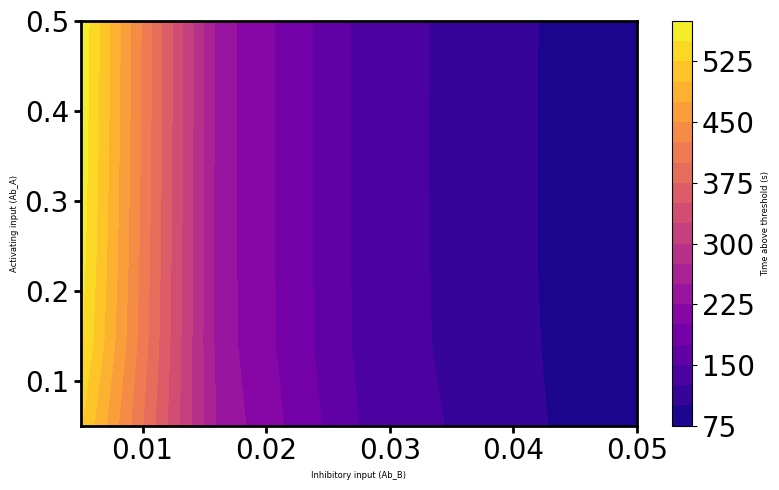

In [ ]:
# Uses: pip_dynamics_model_v4, params, y0, t, LABEL_FS
#
# Ia / Ib are treated as initial antibody concentrations (Ab_A0, Ab_B0).
# The metric is cumulative seconds with PIP3 > 1.


THRESHOLD = 1.0

def time_above_threshold_v4(Ab_A_val, Ab_B_val, params, y0_base, t, threshold=THRESHOLD):
    y0_run = list(y0_base)
    y0_run[12] = Ab_A_val
    y0_run[13] = Ab_B_val
    sol = odeint(pip_dynamics_model_v4, y0_run, t, args=(params,), mxstep=10000)
    dt  = t[1] - t[0]
    return np.sum(sol[:, 10] > threshold) * dt

Ia_values = np.linspace(0.05, 0.5, 6)
Ib_values = np.linspace(0.005, 0.05, 5)
time_above_matrix = np.zeros((len(Ia_values), len(Ib_values)))

for i, Ia in enumerate(Ia_values):
    for j, Ib in enumerate(Ib_values):
        time_above_matrix[i, j] = time_above_threshold_v4(Ia, Ib, params, y0, t)

Ib_grid, Ia_grid = np.meshgrid(Ib_values, Ia_values)

fig, ax = plt.subplots(figsize=(8, 5))
cf = ax.contourf(Ib_grid, Ia_grid, time_above_matrix, levels=20, cmap='plasma')

cbar = plt.colorbar(cf, ax=ax, label='Time above threshold (s)')
cbar.ax.tick_params(labelsize=TICK_FS)
cbar.set_label('Time above threshold (s)', fontsize=LABEL_FS)
ax.set_xlabel('Inhibitory input (Ab_B)', fontsize=LABEL_FS)
ax.set_ylabel('Activating input (Ab_A)', fontsize=LABEL_FS)
#ax.set_title('PIP3 Time Above Threshold', fontsize=14)
style_ax(ax)
plt.tight_layout()
plt.show()
OUTFILE = "TTf sweep"
fig.savefig(f"{OUTFILE}.pdf", bbox_inches="tight")   # vector, for further editing

## Figure 3 — Contour: *TTI* - time for PIP3 to first reach threshold vs (Ia, Ib)

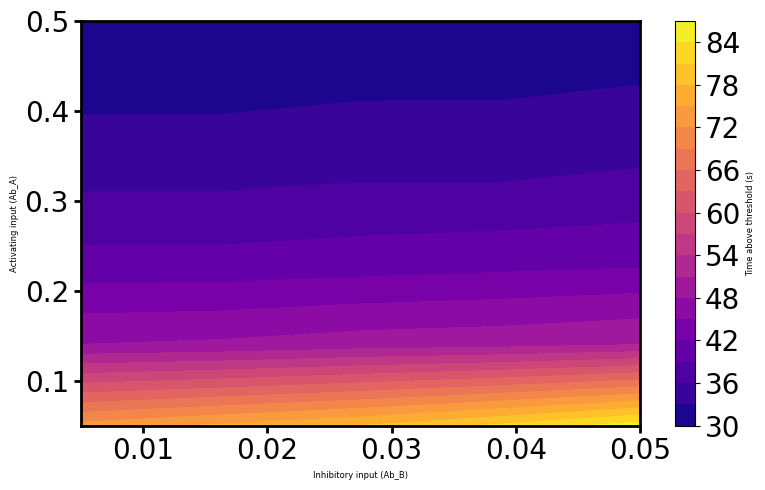

In [ ]:
# Uses: pip_dynamics_model_v4, params, y0, t, LABEL_FS


THRESHOLD = 1.0

def time_to_threshold_v4(Ab_A_val, Ab_B_val, params, y0_base, t, threshold=THRESHOLD):
    y0_run = list(y0_base)
    y0_run[12] = Ab_A_val
    y0_run[13] = Ab_B_val
    sol  = odeint(pip_dynamics_model_v4, y0_run, t, args=(params,), mxstep=10000)
    pip3 = sol[:, 10]
    above = pip3 > threshold
    return t[np.argmax(above)] if np.any(above) else np.nan

Ia_values = np.linspace(0.05, 0.5, 6)
Ib_values = np.linspace(0.005, 0.05, 5)

ttt_matrix = np.zeros((len(Ia_values), len(Ib_values)))

for i, Ia in enumerate(Ia_values):
    for j, Ib in enumerate(Ib_values):
        ttt_matrix[i, j] = time_to_threshold_v4(Ia, Ib, params, y0, t)

Ib_grid, Ia_grid = np.meshgrid(Ib_values, Ia_values)

fig, ax = plt.subplots(figsize=(8, 5))
cf = ax.contourf(Ib_grid, Ia_grid, ttt_matrix, levels=20, cmap='plasma')


cbar = plt.colorbar(cf, ax=ax, label='Time above threshold (s)')
cbar.ax.tick_params(labelsize=TICK_FS)
cbar.set_label('Time above threshold (s)', fontsize=LABEL_FS)
ax.set_xlabel('Inhibitory input (Ab_B)', fontsize=LABEL_FS)
ax.set_ylabel('Activating input (Ab_A)', fontsize=LABEL_FS)
#ax.set_title('Time for PIP3 to Reach Threshold', fontsize=14)
style_ax(ax)
plt.tight_layout()
plt.show()
OUTFILE = "TTI sweep"
fig.savefig(f"{OUTFILE}.pdf", bbox_inches="tight")   # vector, for further editing

NameError: name 'OUTFILE' is not defined

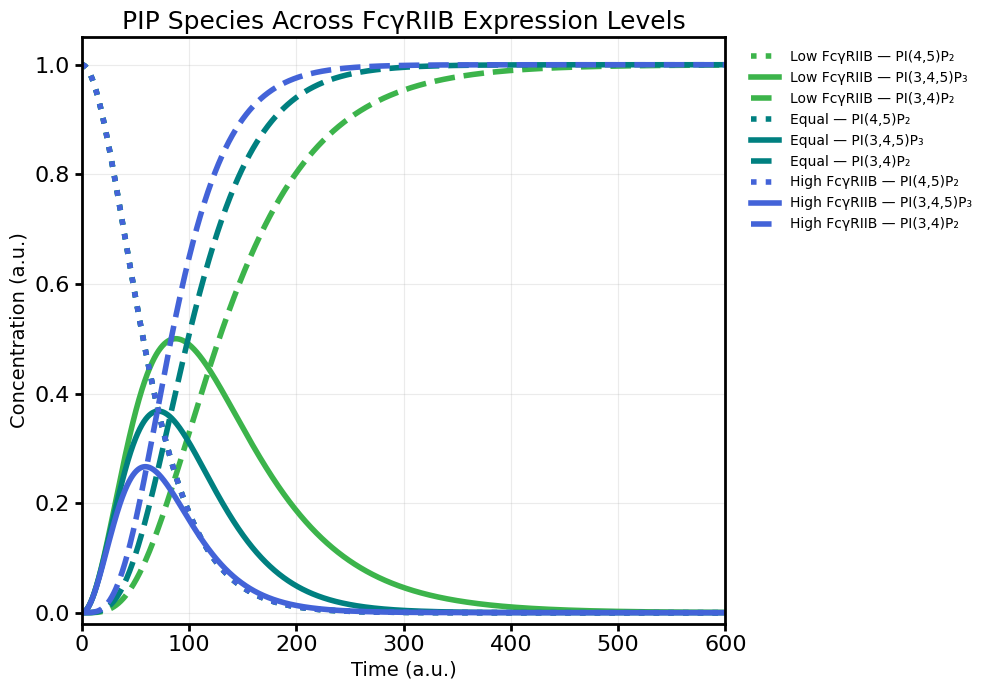

In [ ]:
################### MINIMAL MODEL  ######################
# Minimal activator-inhibitor model — FcgRIIB expression sweep
# All intrinsic rate constants IDENTICAL between activator and inhibitor.
# Only receptor density (and thus amount of recruited inhibitor) changes.
# Demonstrates: transient PIP3 pulse is a structural property of the
# serial dependency; expression level tunes duration.

import numpy as np
from scipy.integrate import odeint
import matplotlib.pyplot as plt

def complete_model(y, t, params, I_func):
    A, B, PIP2, PIP3, PIP2_34 = y
    k_on_A, k_off_A, k_on_B, k_off_B, k_cat_act, k_cat_inh, density_B = params

    I = I_func(t)

    dA_dt = k_on_A * I - k_off_A * A
    dB_dt = density_B * k_on_B * I - k_off_B * B
    dPIP2_dt = - k_cat_act * A * PIP2
    dPIP3_dt = k_cat_act * A * PIP2 - k_cat_inh * B * PIP3
    dPIP2_34_dt = k_cat_inh * B * PIP3

    return [dA_dt, dB_dt, dPIP2_dt, dPIP3_dt, dPIP2_34_dt]

def step_input(t):
    return 1.0 if t > 0 else 0.0

y0 = [0, 0, 1, 0, 0]  # initial [A, B, PIP2, PIP3, PIP2_34]
t  = np.linspace(0, 600, 2400)

k_on = 0.020;  k_off = 0.020;  k_cat_act = 0.030;  k_cat_inh = 0.030

densities = [0.5, 1.0, 1.8]                       # FcgRIIB expression multiplier
colors    = ['#3cb44b', '#008080', '#4363d8']      # green, teal, blue
labels    = ['Low FcγRIIB', 'Equal', 'High FcγRIIB']

solutions = {}
for lbl, dens in zip(labels, densities):
    params = [k_on, k_off, k_on, k_off, k_cat_act, k_cat_inh, dens]
    solutions[lbl] = odeint(complete_model, y0, t, args=(params, step_input), mxstep=10000)

SPINE_LW = 2.0; TICK_LW = 2.0; TICK_LEN = 5; LABEL_FS = 14; TICK_FS = 16; TITLE_FS = 18
def style_ax(ax):
    for spine in ax.spines.values(): spine.set_linewidth(SPINE_LW)
    ax.tick_params(axis='both', which='major', width=TICK_LW, length=TICK_LEN, labelsize=TICK_FS)

fig, ax = plt.subplots(figsize=(10, 7))

for lbl, c in zip(labels, colors):
    ax.plot(t, solutions[lbl][:, 2], color=c, ls=':',  lw=4, label=f'{lbl} — PI(4,5)P₂')
    ax.plot(t, solutions[lbl][:, 3], color=c, ls='-',  lw=4, label=f'{lbl} — PI(3,4,5)P₃')
    ax.plot(t, solutions[lbl][:, 4], color=c, ls='--', lw=4, label=f'{lbl} — PI(3,4)P₂')

ax.set_title('PIP Species Across FcγRIIB Expression Levels', fontsize=TITLE_FS)
ax.set_xlabel('Time (a.u.)', fontsize=LABEL_FS)
ax.set_ylabel('Concentration (a.u.)', fontsize=LABEL_FS)
ax.set_xlim(0, 600); ax.set_ylim(-0.02, 1.05)
ax.grid(True, alpha=0.25)
style_ax(ax)

ax.legend(fontsize=10, frameon=False, loc='upper left', bbox_to_anchor=(1.02, 1.0))

plt.tight_layout()
OUTFILE = "minimal_model"
fig.savefig(f"{OUTFILE}.pdf", bbox_inches="tight")
fig.savefig(f"{OUTFILE}.png", dpi=300, bbox_inches="tight")
plt.show()

## not shown in article figures — Contour: PIP3 peak time vs (Ia, Ib)

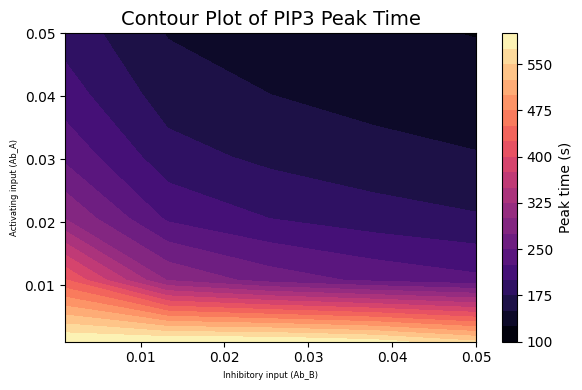

In [ ]:
# Uses: pip_dynamics_model_v4, params, y0, t, LABEL_FS

def peak_time_v4(Ab_A_val, Ab_B_val, params, y0_base, t):
    y0_run = list(y0_base)
    y0_run[12] = Ab_A_val
    y0_run[13] = Ab_B_val
    sol  = odeint(pip_dynamics_model_v4, y0_run, t, args=(params,), mxstep=10000)
    return t[sol[:, 10].argmax()]

Ia_values   = np.linspace(0.001, 0.05, 6)
Ib_values   = np.linspace(0.001, 0.05,  5)
peak_matrix = np.zeros((len(Ia_values), len(Ib_values)))

for i, Ia in enumerate(Ia_values):
    for j, Ib in enumerate(Ib_values):
        peak_matrix[i, j] = peak_time_v4(Ia, Ib, params, y0, t)

Ib_grid, Ia_grid = np.meshgrid(Ib_values, Ia_values)

fig, ax = plt.subplots(figsize=(6, 4))
cf = ax.contourf(Ib_grid, Ia_grid, peak_matrix, levels=20, cmap='magma')
plt.colorbar(cf, ax=ax, label='Peak time (s)')
ax.set_xlabel('Inhibitory input (Ab_B)', fontsize=LABEL_FS)
ax.set_ylabel('Activating input (Ab_A)', fontsize=LABEL_FS)
ax.set_title('Contour Plot of PIP3 Peak Time', fontsize=14)
plt.tight_layout()
plt.show()

## not shown in article figures — inhibitory arm delay

generation : peak 0.02321  t_peak 108.6s  t_half 44.9s
consumption: peak 0.007982  t_peak 187.2s  t_half 97.5s
delay: dt_peak = 78.6s   dt_half = 52.7s


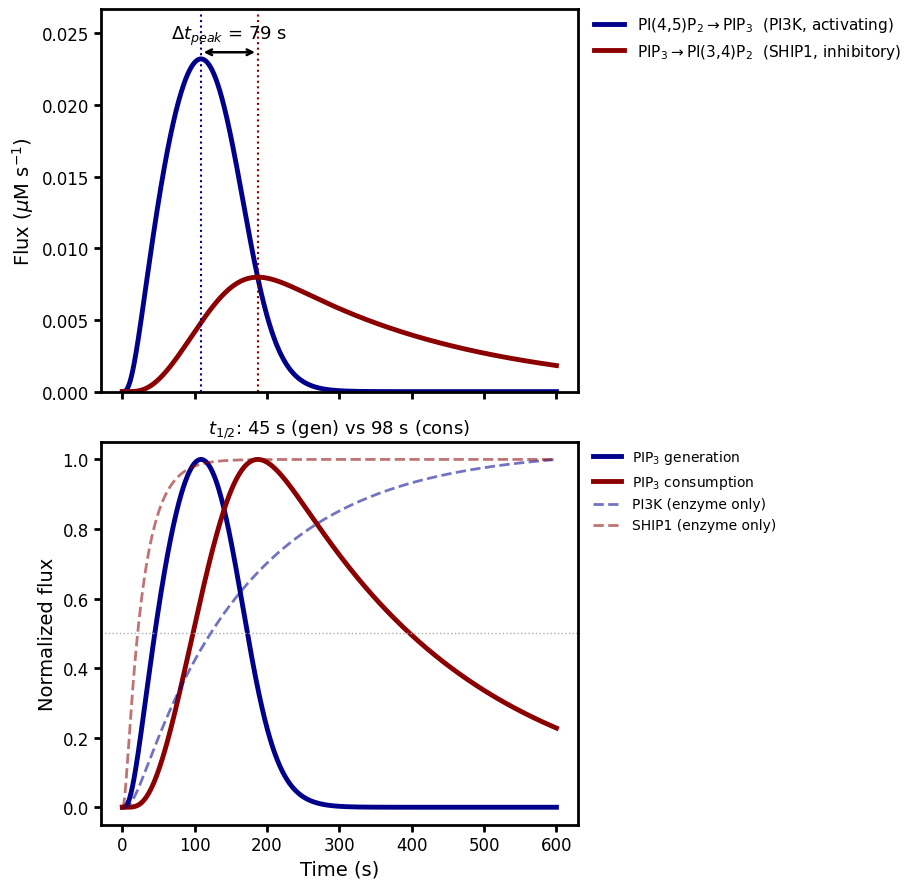

In [ ]:
# ================================================================
# IFFL DELAY: activating vs inhibitory flux through PIP3
# Shows that the inhibitory (SHIP1) flux is temporally delayed
# relative to the activating (PI3K) flux at the convergence node.
# Requires CELL 1 (pip_dynamics_model_v4, params, y0, style_ax).
# ================================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

t_ff = np.linspace(0, 600, 3001)
sol  = odeint(pip_dynamics_model_v4, y0, t_ff, args=(params,), mxstep=10000)

PI3K_, SHIP1_, PIP2_, PIP3_ = sol[:, 7], sol[:, 8], sol[:, 9], sol[:, 10]
gen = k_cat_pi3k  * PI3K_  * (PIP2_ / (Km_pip2 + PIP2_))   # PI(4,5)P2 -> PIP3
con = k_cat_SHIP1 * SHIP1_ * (PIP3_ / (Km_PIP3 + PIP3_))   # PIP3 -> PI(3,4)P2

def _kin(v, t):
    ip = int(np.argmax(v))
    return v[ip], t[ip], float(np.interp(0.5*v[ip], v[:ip+1], t[:ip+1]))

pk_g, tp_g, th_g = _kin(gen, t_ff)
pk_c, tp_c, th_c = _kin(con, t_ff)
print(f"generation : peak {pk_g:.4g}  t_peak {tp_g:.1f}s  t_half {th_g:.1f}s")
print(f"consumption: peak {pk_c:.4g}  t_peak {tp_c:.1f}s  t_half {th_c:.1f}s")
print(f"delay: dt_peak = {tp_c-tp_g:.1f}s   dt_half = {th_c-th_g:.1f}s")

fig, ax = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

# --- absolute fluxes ---
a = ax[0]
a.plot(t_ff, gen, lw=3.5, color=CV4_NOIIB, label=r'PI(4,5)P$_2\to$PIP$_3$  (PI3K, activating)')
a.plot(t_ff, con, lw=3.5, color=CV4_IIB,   label=r'PIP$_3\to$PI(3,4)P$_2$  (SHIP1, inhibitory)')
a.axvline(tp_g, color=CV4_NOIIB, ls=':', lw=1.5)
a.axvline(tp_c, color=CV4_IIB,   ls=':', lw=1.5)
ytop = max(pk_g, pk_c)
a.annotate('', xy=(tp_c, ytop*1.02), xytext=(tp_g, ytop*1.02),
           arrowprops=dict(arrowstyle='<->', lw=1.8, color='k'))
a.text((tp_g+tp_c)/2, ytop*1.06, rf'$\Delta t_{{peak}}$ = {tp_c-tp_g:.0f} s',
       ha='center', fontsize=13)
a.set_ylabel(r'Flux ($\mu$M s$^{-1}$)', fontsize=14)
a.set_ylim(0, ytop*1.15)
a.legend(frameon=False, fontsize=11, loc='upper left', bbox_to_anchor=(1.02, 1.0), borderaxespad=0)

# --- normalized fluxes + upstream enzymes ---
b = ax[1]
b.plot(t_ff, gen/gen.max(), lw=3.5, color=CV4_NOIIB, label='PIP$_3$ generation')
b.plot(t_ff, con/con.max(), lw=3.5, color=CV4_IIB,   label='PIP$_3$ consumption')
b.plot(t_ff, PI3K_/PI3K_.max(),  lw=2, ls='--', alpha=0.55, color=CV4_NOIIB, label='PI3K (enzyme only)')
b.plot(t_ff, SHIP1_/SHIP1_.max(), lw=2, ls='--', alpha=0.55, color=CV4_IIB,   label='SHIP1 (enzyme only)')
b.axhline(0.5, color=CTHR, lw=1, ls=':')
b.set_xlabel('Time (s)', fontsize=14)
b.set_ylabel('Normalized flux', fontsize=14)
b.set_title(rf'$t_{{1/2}}$: {th_g:.0f} s (gen) vs {th_c:.0f} s (cons)', fontsize=13)
b.legend(frameon=False, fontsize=10, loc='upper left', bbox_to_anchor=(1.02, 1.0), borderaxespad=0)

for x in ax:
    style_ax(x)
    x.tick_params(labelsize=12)
plt.tight_layout(rect=[0, 0, 0.78, 1])
fig.savefig('IFFL_delay_fluxes.pdf', bbox_inches='tight')
fig.savefig('IFFL_delay_fluxes.png', dpi=300, bbox_inches='tight')
plt.show()